# Case 3: wildfires seen by NISAR radar (2026)

NISAR is the new NASA and ISRO radar satellite. Its L-band radar (24 cm wavelength) goes through smoke and clouds and reaches into the forest canopy. In this case we use it to map **where forests burned** in 2026.

Two fires are studied with the same method:
- **Part A: the Bald Range wildfire**, Summerland, British Columbia (August 2026).
- **Part B: the Thunder Bay 36 wildfire**, northwestern Ontario (July 2026), added later.

This notebook, read from top to bottom:

**Part A: Bald Range**
1. **Study area**: where the fire burned, on a satellite photo, with the official fire perimeter.
2. **Data**: which NISAR files, and how we fetch them with NASA's API.
3. **The raw radar**: before and after the fire, and how we clean the speckle.

The main radar channel is **HV** (explained in section A2): it measures the forest canopy, so it drops where the canopy burned.

In [1]:
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path

import earthaccess
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401  (adds the .rio tools to xarray)
import xarray as xr
from matplotlib.patches import Patch
from pyproj import Transformer
from rasterio.features import geometry_mask
from scipy import ndimage

DATA = Path("../data/case3")      # this notebook lives in dataScience/notebooks/
CACHE = DATA / "cache"            # downloads (large, not committed to git)
EXPORT = DATA / "export"          # the packages for the app (small, committed), one folder per fire
CACHE.mkdir(parents=True, exist_ok=True)
EXPORT.mkdir(parents=True, exist_ok=True)
PIXEL_M = 20                      # analysis pixel size (metres)

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "font.size": 9})

### Map helpers

Each fire gets its own grid: 20 m pixels in the UTM zone of the fire, covering its study box. Every radar date and every photo is resampled onto that grid, so pixel `[row, col]` is the same spot on the ground in every image. The helpers below take the grid as input, so Part A and Part B share them.

In [2]:
def make_grid(bbox, epsg, res=PIXEL_M):
    """Empty grid (UTM, 20 m) that covers the lon/lat box."""
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([bbox[0], bbox[2], bbox[0], bbox[2]], [bbox[1], bbox[1], bbox[3], bbox[3]])
    x0, x1 = np.floor(min(xs) / res) * res, np.ceil(max(xs) / res) * res
    y0, y1 = np.floor(min(ys) / res) * res, np.ceil(max(ys) / res) * res
    x = np.arange(x0 + res / 2, x1, res)
    y = np.arange(y1 - res / 2, y0, -res)
    return xr.DataArray(np.zeros((y.size, x.size), "float32"), coords={"y": y, "x": x}, dims=("y", "x")).rio.write_crs(epsg)


def extent(grid):
    h = PIXEL_M / 2
    return [float(grid.x[0]) - h, float(grid.x[-1]) + h, float(grid.y[-1]) - h, float(grid.y[0]) + h]


def lonlat_to_grid(grid, lon, lat):
    return Transformer.from_crs(4326, grid.rio.crs, always_xy=True).transform(lon, lat)


def box_xy(grid, w, s, e, n):
    """Outline of a lon/lat box in grid coordinates (for drawing)."""
    return lonlat_to_grid(grid, [w, e, e, w, w], [s, s, n, n, s])


def zoom_to(ax, grid, w, s, e, n):
    xs, ys = box_xy(grid, w, s, e, n)
    ax.set_xlim(min(xs), max(xs))
    ax.set_ylim(min(ys), max(ys))


def scale_bar(ax, km=5):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x, y = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color="white", lw=3)
    ax.text(x + km * 500, y + 0.015 * (y1 - y0), f"{km} km", color="white", ha="center", fontsize=8)


def clean_axes(ax, title):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def show_radar(ax, grid, db, title, vmin=-25, vmax=-5):
    """Grey radar image in dB: dark = little echo, bright = strong echo."""
    im = ax.imshow(db, cmap="gray", vmin=vmin, vmax=vmax, extent=extent(grid), interpolation="nearest")
    clean_axes(ax, title)
    return im


def show_classes(ax, grid, codes, colors):
    """Colour the pixels whose code is in `colors` ({code: hex}); others stay transparent."""
    rgba = np.zeros(codes.shape + (4,), "uint8")
    for k, hexcol in colors.items():
        rgba[codes == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    ax.imshow(rgba, extent=extent(grid), interpolation="nearest")


def draw_outline(ax, gdf, grid, color="#ff7f00", lw=1.6, label=None):
    """Draw polygon outlines (for example the official fire perimeter) on a grid map."""
    for geom in gdf.to_crs(grid.rio.crs).geometry:
        for poly in getattr(geom, "geoms", [geom]):
            ax.plot(*poly.exterior.xy, color=color, lw=lw, label=label)
            label = None


def inside_mask(gdf, grid):
    """True on the grid pixels inside the polygons."""
    return ~geometry_mask(gdf.to_crs(grid.rio.crs).geometry, out_shape=grid.shape, transform=grid.rio.transform())

### Data helpers

The same three sources as in case 2, written once for both fires:
- **Sentinel-2** photos from the free **Earth Search** catalogue (no login).
- **OpenStreetMap** place names (Overpass API).
- **NISAR** radar files from NASA Earthdata (free account, password in `~/.netrc`). We read **only the pixels of the study box** from each 4 to 7 GB file.

In [3]:
STAC = "https://earth-search.aws.element84.com/v1/search"
GROUP = "/science/LSAR/GCOV/grids/frequencyA"   # where the 20 m HH and HV images sit in a NISAR GCOV file


def stac_search(collection, bbox, day):
    """Images of one collection that touch the box on one day (public STAC API)."""
    body = {"collections": [collection], "bbox": list(bbox), "limit": 20,
            "datetime": f"{day}T00:00:00Z/{day}T23:59:59Z"}
    req = urllib.request.Request(STAC, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=120))["features"]


def sentinel2_photo(key, grid, bbox, day):
    """True-colour Sentinel-2 photo on the grid; tiles are read over the internet, only the box is kept."""
    path = CACHE / f"{key}_sentinel2_{day}.tif"
    if path.exists():
        return rioxarray.open_rasterio(path)
    items = sorted(stac_search("sentinel-2-l2a", bbox, day), key=lambda f: f["properties"]["eo:cloud_cover"])
    rgb = None
    for item in items:
        tile = rioxarray.open_rasterio(item["assets"]["visual"]["href"], overview_level=0)  # 20 m version
        try:
            tile = tile.rio.clip_box(*bbox, crs="EPSG:4326")
        except Exception:
            continue  # this tile does not touch the box
        part = tile.rio.reproject_match(grid, nodata=0)
        rgb = part if rgb is None else rgb.where((rgb != 0).any("band"), part)
        print(f"  {item['id']}: {item['properties']['eo:cloud_cover']:.1f} % cloud")
    rgb = rgb.astype("uint8").rio.write_crs(grid.rio.crs)
    rgb.rio.to_raster(path, compress="deflate")
    return rgb


import osmnx as ox

OVERPASS = ("https://overpass-api.de/api", "https://overpass.kumi.systems/api")
ox.settings.cache_folder = str(CACHE / "osmnx")   # osmnx's own download cache, kept with ours (not committed)


def osm(bbox, tags, name):
    """OpenStreetMap features in the box (Overpass API), cached as GeoJSON."""
    path = CACHE / f"osm_{name}.geojson"
    if path.exists():
        return gpd.read_file(path)
    for attempt in range(3):
        for url in OVERPASS:
            try:
                ox.settings.overpass_url = url
                gdf = ox.features_from_bbox(bbox, tags).reset_index()
                cols = [c for c in ("name", "place", "natural", "waterway") if c in gdf.columns]
                gdf = gdf[cols + ["geometry"]]
                gdf.to_file(path, driver="GeoJSON")
                return gdf
            except Exception as exc:
                print(f"  Overpass {url} failed ({type(exc).__name__}), trying again")
        time.sleep(20 * (attempt + 1))
    raise RuntimeError("OpenStreetMap is not reachable right now; run this cell again later")


def to_db(power):
    """Echo power (ratio) to decibels: dB = 10 * log10(power)."""
    return 10 * np.log10(np.where(power > 0, power, np.nan))


def read_window(url, grid):
    """Stream only the grid's box from one NISAR file: HH and HV echo power, averaged to 20 m."""
    fs = earthaccess.get_fsspec_https_session()
    with fs.open(url, "rb", cache_type="blockcache", block_size=8 * 2**20) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", group=GROUP, phony_dims="sort",
                             drop_variables=["listOfCovarianceTerms", "listOfPolarizations"])
        epsg = int(ds["projection"].attrs.get("epsg_code", ds["projection"].values))
        assert epsg == grid.rio.crs.to_epsg(), f"unexpected map projection EPSG:{epsg}"
        x, y = ds["xCoordinates"].values, ds["yCoordinates"].values
        xmin, ymin, xmax, ymax = grid.rio.bounds()
        cols = np.where((x > xmin - 40) & (x < xmax + 40))[0]
        rows = np.where((y > ymin - 40) & (y < ymax + 40))[0]
        win = ds[["HHHH", "HVHV"]].isel(xCoordinates=slice(cols[0], cols[-1] + 1),
                                         yCoordinates=slice(rows[0], rows[-1] + 1)).load()
    win = win.rename(xCoordinates="x", yCoordinates="y")
    step = abs(float(x[1] - x[0]))
    if step < PIXEL_M:  # 10 m product: average blocks of 2 x 2 pixels (as echo power, before dB)
        f = int(round(PIXEL_M / step))
        win = win.coarsen(x=f, y=f, boundary="trim").mean()
    return win.rio.write_crs(epsg)


def load_date(key, row, grid):
    """HH and HV in dB on the grid for one date (cached after the first download)."""
    path = CACHE / f"nisar_{key}_{row.date}.nc"
    if not path.exists():
        t0 = time.time()
        for attempt in range(3):   # NASA's server sometimes answers "502 Bad Gateway": wait and try again
            try:
                win = read_window(row.url, grid).rio.reproject_match(grid)
                break
            except Exception as exc:
                if attempt == 2:
                    raise
                print(f"  {row.date}: {type(exc).__name__}, trying again in {30 * (attempt + 1)} s")
                time.sleep(30 * (attempt + 1))
        out = xr.Dataset({"HH": grid.copy(data=to_db(win["HHHH"].values).astype("float32")),
                          "HV": grid.copy(data=to_db(win["HVHV"].values).astype("float32"))})
        out.attrs = {"file": row.file, "mode": row["mode"], "units": "dB"}
        out.to_netcdf(path)
        print(f"  {row.date}: streamed in {time.time() - t0:.0f} s")
    return xr.open_dataset(path).load()


def despeckle(db, size=5):
    """5 x 5 median filter that keeps the no-data gaps (same cleaning as case 2)."""
    a = db.values
    ok = np.isfinite(a)
    out = ndimage.median_filter(np.where(ok, a, np.nanmedian(a)), size=size)
    out[~ok] = np.nan
    return db.copy(data=out.astype("float32"))


def nisar_files(bbox, start, end):
    """Table of the NISAR GCOV files that touch the box between two dates (NASA CMR search, no login)."""
    rows = []
    for g in earthaccess.search_data(short_name="NISAR_L2_GCOV_PROVISIONAL_V1", bounding_box=bbox, temporal=(start, end)):
        name = g["umm"]["GranuleUR"]
        p = name.split("_")  # NISAR_L2_PR_GCOV_<cycle>_<track>_<A|D>_<frame>_<mode>_<pols>_<..>_<start>_<end>_<..>_N_<F|P>_..
        url = [u for u in g.data_links(access="external") if u.endswith(".h5")][0]
        rows.append({"date": f"{p[11][:4]}-{p[11][4:6]}-{p[11][6:8]}", "track": p[5] + p[6], "frame": p[7],
                     "mode": p[8], "channels": p[9], "full_frame": p[-3] == "F", "file": name, "url": url})
    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True)

# Part A: the Bald Range wildfire (Summerland, British Columbia)

## A1. The study area, seen from space

The fire started on the evening of **August 7, 2026** in the Faulder area, west of **Summerland**, in the Okanagan valley. Pushed by strong winds it grew to about **10,300 ha in two days**; British Columbia declared a **provincial state of emergency** on August 8, about 20,000 people were evacuated and about **150 structures** were damaged or destroyed. The BC Wildfire Service mapped its final perimeter at **25,163 ha** (fire number **K51490**) on August 29.

The photo below is a normal colour image from **Sentinel-2** on **August 4, 2026**, three days before the fire. The orange line is the **official fire perimeter** from the BC Wildfire Service (BC Data Catalogue, public, no login): it is our reference to check the radar result.

In [4]:
KEY_A = "bald_range"
BBOX_A = (-120.05, 49.48, -119.63, 49.74)   # study box: west, south, east, north (degrees)
UTM_A = 32611                               # UTM zone 11N: the map grid of the NISAR files here
FIRE_START_A = "2026-08-07"
GRID_A = make_grid(BBOX_A, UTM_A)
print(f"Grid: {GRID_A.sizes['y']} x {GRID_A.sizes['x']} pixels of {PIXEL_M} m, EPSG:{UTM_A}")


def bc_fire_perimeter(fire_number):
    """Official fire perimeter from the BC Wildfire Service (BC Data Catalogue WFS, public), cached."""
    path = CACHE / f"bc_perimeter_{fire_number}.geojson"
    if not path.exists():
        q = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "outputFormat": "application/json",
             "typeName": "WHSE_LAND_AND_NATURAL_RESOURCE.PROT_CURRENT_FIRE_POLYS_SP", "srsName": "EPSG:4326",
             "CQL_FILTER": f"FIRE_NUMBER='{fire_number}'"}
        url = "https://openmaps.gov.bc.ca/geo/pub/wfs?" + urllib.parse.urlencode(q)
        features = json.load(urllib.request.urlopen(url, timeout=120))["features"]
        gpd.GeoDataFrame.from_features(features, crs=4326).to_file(path, driver="GeoJSON")
    return gpd.read_file(path)


perimeter_A = bc_fire_perimeter("K51490")
INSIDE_A = inside_mask(perimeter_A, GRID_A)
p = perimeter_A.iloc[0]
print(f"Official perimeter K51490: {p['FIRE_SIZE_HECTARES']:,.0f} ha, mapped {str(p['TRACK_DATE'])[:10]}, status {p['FIRE_STATUS']}")
print(f"On our grid: {INSIDE_A.sum() * PIXEL_M**2 / 1e6:.1f} km² inside the perimeter")

Grid: 1503 x 1572 pixels of 20 m, EPSG:32611
Official perimeter K51490: 25,163 ha, mapped 2026-08-29, status Out
On our grid: 251.7 km² inside the perimeter


In [5]:
PHOTO_BEFORE_A = "2026-08-04"
photo_A = sentinel2_photo(KEY_A, GRID_A, BBOX_A, PHOTO_BEFORE_A)
photo_A_rgb = np.moveaxis(photo_A.values, 0, -1)

places_A = osm(BBOX_A, {"place": ["city", "town", "village", "hamlet", "locality"]}, f"{KEY_A}_places")
places_A = places_A[(places_A.geometry.geom_type == "Point") & places_A["name"].notna()].reset_index(drop=True)
print("Places:", ", ".join(places_A["name"]))

# Map of Canada for the small locator inset (Natural Earth, public domain)
world_path = CACHE / "natural_earth_countries.geojson"
if not world_path.exists():
    gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip").to_file(world_path, driver="GeoJSON")
world = gpd.read_file(world_path)

Places: Summerland, Faulder, Meadow Valley, Crescent Beach, Greata, Wild Horse Canyon, West Bench


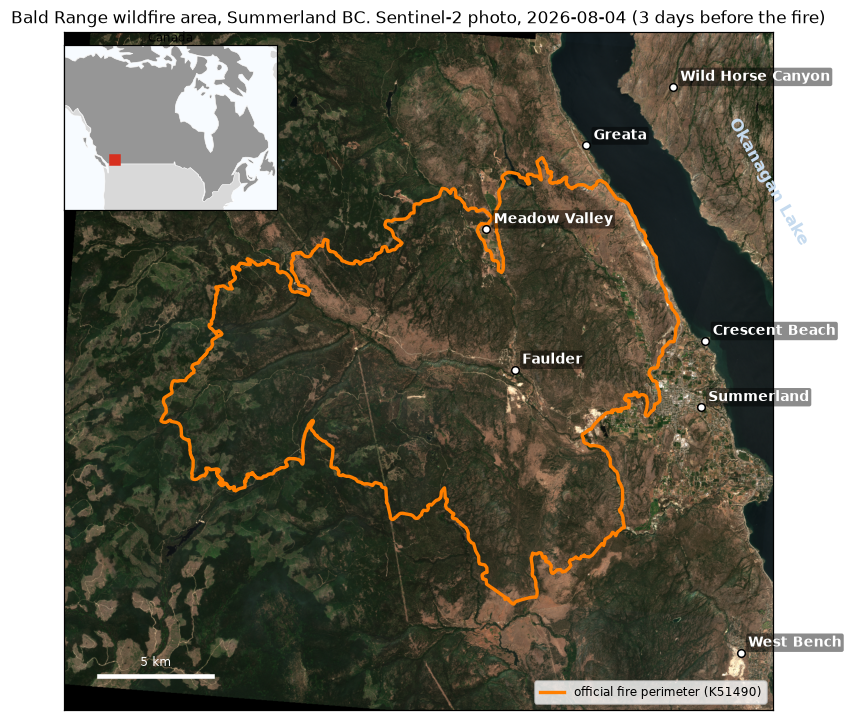

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(photo_A_rgb, extent=extent(GRID_A))
draw_outline(ax, perimeter_A, GRID_A, lw=2.2, label="official fire perimeter (K51490)")
for _, t in places_A.to_crs(UTM_A).iterrows():
    ax.plot(t.geometry.x, t.geometry.y, "o", ms=5, mfc="white", mec="black")
    ax.annotate(t["name"], (t.geometry.x, t.geometry.y), xytext=(5, 4), textcoords="offset points",
                color="white", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.45, lw=0))
lx, ly = lonlat_to_grid(GRID_A, -119.655, 49.665)
ax.annotate("Okanagan Lake", (lx, ly), color="#c6dbef", fontsize=11, fontweight="bold", rotation=-60)
ax.set_xlim(extent(GRID_A)[:2])
ax.set_ylim(extent(GRID_A)[2:])
clean_axes(ax, f"Bald Range wildfire area, Summerland BC. Sentinel-2 photo, {PHOTO_BEFORE_A} (3 days before the fire)")
ax.legend(loc="lower right", fontsize=8)
scale_bar(ax)

inset = ax.inset_axes([0.0, 0.72, 0.30, 0.28])
world.plot(ax=inset, color="#d9d9d9", edgecolor="white", lw=0.4)
world[world["NAME"] == "Canada"].plot(ax=inset, color="#969696", edgecolor="white", lw=0.4)
inset.plot(np.mean(BBOX_A[::2]), np.mean(BBOX_A[1::2]), "s", color="#d7301f", ms=6)
inset.set_xlim(-141, -52)
inset.set_ylim(40, 72)
for f in (inset.set_xticks, inset.set_yticks):
    f([])
inset.set_xlabel("")
inset.set_ylabel("")
inset.set_facecolor("#f7fbff")
inset.set_title("Canada", fontsize=8, pad=2)
plt.show()

## A2. The NISAR data and how we fetch it

| | |
|---|---|
| Satellite | NISAR (NASA and ISRO), launched July 2025 |
| Radar | **L-band**, 24 cm wavelength: passes through smoke and reaches into the canopy |
| Product | **GCOV level 2** (calibrated backscatter on a map grid), collection `NISAR_L2_GCOV_PROVISIONAL_V1` |
| Pixel | delivered at 10 m here; we average 2 x 2 pixels to 20 m |
| Channels used | **HV** (main) and HH (for comparison) |
| Archive | NASA Earthdata (Alaska Satellite Facility), free account, password in `~/.netrc` |

**Why HV for a forest fire.** The radar sends a horizontal wave (H) and listens in two ways:
- **HV** (horizontal sent, vertical received) only comes back when the wave bounces many times inside a **volume** of leaves, needles and branches. It measures the **canopy**. When the canopy burns, there is less to bounce in, so **HV drops**.
- **HH** reacts more to the ground, trunks and moisture. In case 2 it was the flood channel; here it is shown for comparison only.

The search below asks NASA's catalogue (CMR) for every NISAR file over the box from June to mid-November 2026.

In [7]:
files_A = nisar_files(BBOX_A, "2026-06-01", "2026-11-14")
print(f"{len(files_A)} NISAR files touch the box, per pass (track and frame):")
print(files_A.groupby(["track", "frame"]).date.nunique().rename("dates").to_string())

65 NISAR files touch the box, per pass (track and frame):
track  frame
005A   026       9
       027       9
071D   063      10
       064      10
077A   027       9
149A   027       9
172D   063       9


Several passes cover the fire. We keep **track 071D, frame 063** (descending orbit): it covers the whole perimeter on every date, gives the same acquisition mode on all 10 dates (June 19 to October 17), and has a pass **13 days before ignition (July 25)**. No pass is closer: NISAR has no data between July 27 and August 10, 2026.

| Role | Date | Why |
|---|---|---|
| **Before** | **2026-07-25** | last pass before the fire started (August 7) |
| **After** | **2026-09-11** | the fire is out (perimeter final on August 29); the August 30 pass is wet after rain and misses part of the area |

In [8]:
use_A = files_A[(files_A.track == "071D") & (files_A.frame == "063") & (files_A.channels == "DHDH") & files_A.full_frame]
use_A = use_A.drop_duplicates("date").reset_index(drop=True)
DATES_A = list(use_A.date)
BEFORE_A, AFTER_A = "2026-07-25", "2026-09-11"
use_A[["date", "mode", "channels", "file"]]

,date,mode,channels,file
0,2026-06-19,4005,DHDH,NISAR_L2_PR_GCOV_023_071_D_063_4005_DHDH_A_202...
1,2026-07-01,4005,DHDH,NISAR_L2_PR_GCOV_024_071_D_063_4005_DHDH_A_202...
2,2026-07-13,4005,DHDH,NISAR_L2_PR_GCOV_025_071_D_063_4005_DHDH_A_202...
3,2026-07-25,4005,DHDH,NISAR_L2_PR_GCOV_026_071_D_063_4005_DHDH_A_202...
4,2026-08-18,4005,DHDH,NISAR_L2_PR_GCOV_028_071_D_063_4005_DHDH_A_202...
5,2026-08-30,4005,DHDH,NISAR_L2_PR_GCOV_029_071_D_063_4005_DHDH_A_202...
6,2026-09-11,4005,DHDH,NISAR_L2_PR_GCOV_030_071_D_063_4005_DHDH_A_202...
7,2026-09-23,4005,DHDH,NISAR_L2_PR_GCOV_031_071_D_063_4005_DHDH_A_202...
8,2026-10-05,4005,DHDH,NISAR_L2_PR_GCOV_032_071_D_063_4005_DHDH_A_202...
9,2026-10-17,4005,DHDH,NISAR_L2_PR_GCOV_033_071_D_063_4005_DHDH_A_202...


### Reading each date

For each date: open the file over HTTPS, keep the box, average the 10 m pixels to 20 m (as echo power, before converting), put it on our grid and convert to **decibels**:

$$\text{dB} = 10 \cdot \log_{10}(\text{echo power})$$

The first run streams about 50 seconds per date from NASA; the result is cached in `data/case3/cache/`.

In [9]:
earthaccess.login(strategy="netrc")
scenes = [load_date(KEY_A, r, GRID_A) for _, r in use_A.iterrows()]
RAW_A = xr.concat(scenes, dim=pd.Index(DATES_A, name="date")).rio.write_crs(UTM_A)   # HH and HV (dB) as delivered
del scenes
pd.DataFrame({"date": DATES_A,
              "valid pixels in the box %": [round(float(np.isfinite(RAW_A.HV.sel(date=d)).mean() * 100), 1) for d in DATES_A],
              "perimeter covered %": [round(float(np.isfinite(RAW_A.HV.sel(date=d).values[INSIDE_A]).mean() * 100), 1) for d in DATES_A]})

,date,valid pixels in the box %,perimeter covered %
0,2026-06-19,90.9,100.0
1,2026-07-01,85.2,100.0
2,2026-07-13,94.1,100.0
3,2026-07-25,88.3,100.0
4,2026-08-18,88.0,100.0
5,2026-08-30,73.7,97.3
6,2026-09-11,77.9,99.7
7,2026-09-23,76.4,99.1
8,2026-10-05,69.2,91.9
9,2026-10-17,61.3,75.4


## A3. The raw radar: before and after

HV on the same grey scale on both dates (-25 dB black, -5 dB white), with the official perimeter in orange. Forest is bright in HV (a lot of canopy to bounce in); lakes, bare rock and open grassland are dark. Look inside the perimeter: some areas got **darker** after the fire, while the change is small elsewhere.

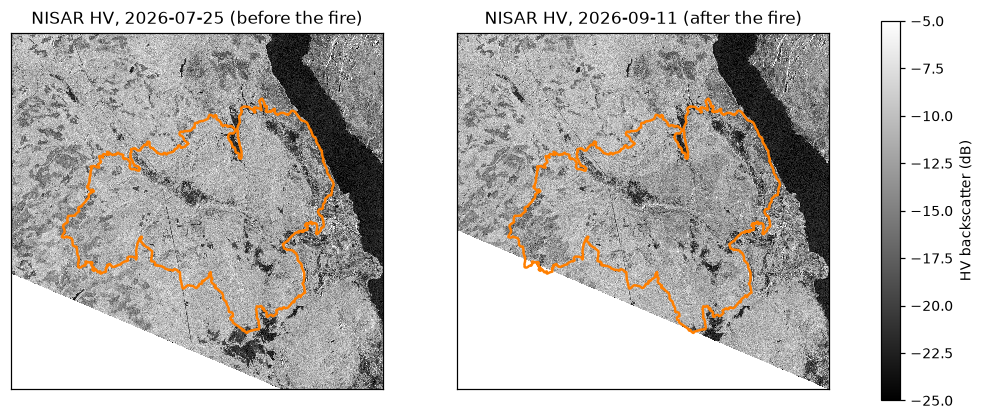

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, d, label in zip(axes, (BEFORE_A, AFTER_A), ("before the fire", "after the fire")):
    im = show_radar(ax, GRID_A, RAW_A.HV.sel(date=d), f"NISAR HV, {d} ({label})")
    draw_outline(ax, perimeter_A, GRID_A)
    scale_bar(ax)
fig.colorbar(im, ax=axes, shrink=0.8, label="HV backscatter (dB)")
plt.show()

### Speckle, and how we clean it

As in case 2, each radar pixel is grainy (**speckle**): a pixel can jump by several dB with no change on the ground. We replace each pixel by the **median of the 5 x 5 pixels** around it (100 m by 100 m). All rules use this cleaned image; the raw one is kept to compare in the app.

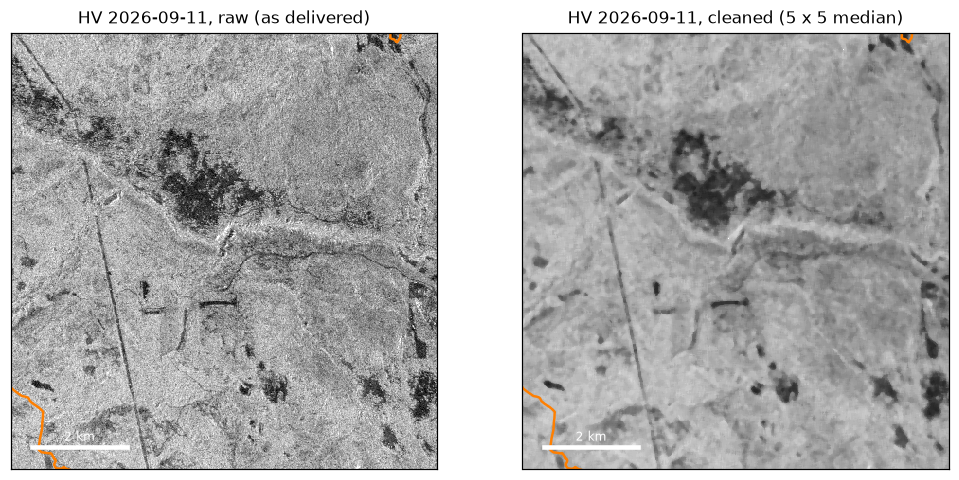

In [11]:
CLEAN_A = xr.Dataset({b: xr.concat([despeckle(RAW_A[b].sel(date=d)) for d in DATES_A], dim=pd.Index(DATES_A, name="date"))
                      for b in ("HH", "HV")}).rio.write_crs(UTM_A)

ZOOM_A = (-119.90, 49.57, -119.78, 49.65)   # about 9 km x 9 km in the middle of the burn, used for close-ups
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
for ax, img, label in zip(axes, (RAW_A, CLEAN_A), ("raw (as delivered)", "cleaned (5 x 5 median)")):
    show_radar(ax, GRID_A, img.HV.sel(date=AFTER_A), f"HV {AFTER_A}, {label}")
    draw_outline(ax, perimeter_A, GRID_A)
    zoom_to(ax, GRID_A, *ZOOM_A)
    scale_bar(ax, km=2)
plt.show()

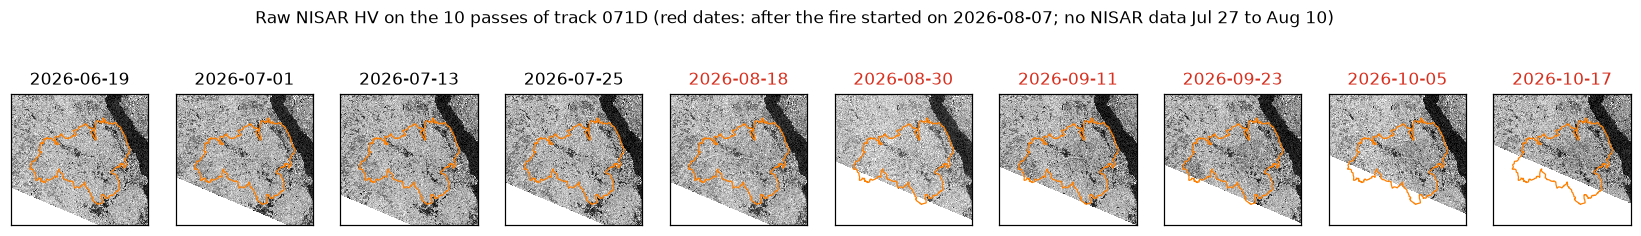

In [12]:
fig, axes = plt.subplots(1, len(DATES_A), figsize=(1.9 * len(DATES_A), 2.4))
for ax, d in zip(axes, DATES_A):
    show_radar(ax, GRID_A, RAW_A.HV.sel(date=d).values[::2, ::2], d)
    draw_outline(ax, perimeter_A, GRID_A, lw=0.8)
    ax.title.set_color("#d7301f" if d > FIRE_START_A else "black")
fig.suptitle(f"Raw NISAR HV on the {len(DATES_A)} passes of track 071D (red dates: after the fire started on {FIRE_START_A}; no NISAR data Jul 27 to Aug 10)", y=1.06)
plt.show()